<a href="https://colab.research.google.com/github/Luuuuuig/Bachelor-End-Project/blob/main/Focal_Case_Selection_2026-10-07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Selecting the focal case
**7 October 2026 · Yijie's provisional assessment, before Zhongxin's**

This notebook applies the two-stage selection rule of the [methodology (§5.3)](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/methodology/Phase_1_Current_Methodology.md#53-formal-two-stage-selection-rule) to the six candidate areas from the [analysis notebook](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/Arno_Analysis_2026_10_02.ipynb): veto gates first (Stage A), then a weighted comparison of the candidates that remain (Stage B), then a sensitivity check. It addresses SQ3 (focal-case selection), using SQ1 evidence on workload, causes and workflow. The proposed implementation controls relate to SQ2 and the evaluation conditions to SQ4; neither is a completed implementation or evaluation.

## Summary

- **Provisional focal case: purchase-price control.** Support for checking supplier quotations and order confirmations against the PO: read the price and delivery date per line from the supplier's document, match the lines to the PO and flag differences for the buyer, who decides. Nothing changes in Exact without the buyer.
- **Stage A:** two of the six candidates leave the comparison. PO supplier communication fails gate 6 (ordinary automation is enough), and standard / review / manual fails gate 5 as a stand-alone candidate (it stays the design frame of the focal case). Maximalisatie and request intake continue only with a narrower output, defined in part 2; price control and article data pass provisionally.
- **Stage B:** price control scores **76.2 of 100**, ahead of article data (56.8), maximalisatie (51.9) and request intake (50.8). It scores highest or joint highest on every criterion.
- **Sensitivity:** price control stays first in every single-change check: equal weights, each weight ±20%, each score ±1, and the price-only boundary. Combinations of plausible changes can reverse the ranking: six one-point changes within the recorded ranges put article data ahead, four of them on price control's own scores, including data readiness and evaluation.
- **Permission:** Johan's permission covers the test-account data and processing its documents with an external AI service (checks G1–G2, confirmed by Yijie on 7 October), so gate 1 passes for price control.
- **Open gates:** price control passes gates 2 and 3 only provisionally. If the test account lacks confirmations or a traceable approved price (checks PC1–PC4), those gates reopen, and another data source and reference must be shown to work before scoring continues; a lower score does not settle a failed gate.
- **Next:** resolve the source and reference checks, confirm Arno's acceptance and Johan's assessment of business value, and complete the targeted classification review. Zhongxin sets her own weights without seeing these results, then reviews the gates, scores and focal case.

## Status and order of work

- **Provisional.** Several gates and scores rest on evidence that is expected but not yet seen, mainly in the Exact test account. Each such verdict names the check that settles it, using the IDs of the [Stage A worksheet](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Stage_A_Test_Account_Check_2026-10-07.xlsx). Each score has a low and a high value for that uncertainty.
- **Weights before scores.** The weights are Yijie's swing weights, [recorded](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Swing_Weights_Yijie_2026-10-07.md) and committed on 7 October before any candidate was scored.
- **Zhongxin's assessment follows.** She sets her own swing weights without seeing these results, then reviews the gates, the scores and the focal case. Her weights are then added to the sensitivity check.
- **Evidence.** Every verdict and score cites the [evidence matrix](https://github.com/Luuuuuig/Bachelor-End-Project/blob/main/docs/analyze/Candidate_Evidence_Matrix_2026-10-07.md); minutes are recorded minutes without former EXC, out of 560, from five sessions of one buyer. The analysis notebook's targeted review of decision-relevant and ambiguous labels across competing candidates is pending; the 45-record blind sample and kappa are optional, not a required selection gate.

## 1. Load the inputs

As in the course notebooks, the libraries are loaded once and the plot defaults set here. The weights, gate verdicts and scores are CSV files in `docs/analyze`, loaded from the fixed repository commit in the loading cell. This preserves the provisional assessment behind the saved numerical results. The linked current methodology and review plan may be newer; narrative clarification does not itself update those inputs. New evidence, revised scores or Zhongxin's weights require an updated input snapshot and a rerun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plots, as in the course notebooks
sns.set()                                  # set Seaborn defaults
plt.rcParams["figure.figsize"] = 10, 5     # default hor./vert. size of plots, in inches

In [2]:
# All inputs come from one version of the repository
commit = "1aef580bbefd1368bc8fee9a6a0007efddf918a3"
repo = f"https://raw.githubusercontent.com/Luuuuuig/Bachelor-End-Project/{commit}/"

weights = pd.read_csv(repo + "docs/analyze/Swing_Weights_Yijie_2026-10-07.csv").set_index("criterion")
gates = pd.read_csv(repo + "docs/analyze/Stage_A_Gates_2026-10-07.csv", keep_default_na=False)
scores = pd.read_csv(repo + "docs/analyze/Candidate_Scores_2026-10-07.csv")

# Swing weights: each swing divided by the total
weights["weight"] = weights["swing"] / weights["swing"].sum()
weights.round(3)

,label,swing,weight
criterion,,,
workload,Observed workload contribution,100,0.270
business_value,Business value beyond counted workload,40,0.108
ai_fit,AI–task fit,50,0.135
data_readiness,Data readiness above the gate minimum,60,0.162
repetition,Repetition / process standardisation,30,0.081
prototype,Prototype / technical feasibility,40,0.108
evaluation,Evaluation feasibility,50,0.135


## 2. Stage A: veto gates

Each candidate is checked against six gates. A failed gate cannot be made up by a high score.

| Gate | Question |
|---|---|
| 1 | Are the required data and tools permitted for the research use? |
| 2 | Are the accessible data representative enough for a prototype and a test? |
| 3 | Can a reproducible reference answer and manual baseline be created? |
| 4 | Are critical errors detectable or reversible, with human review, an audit trail and a fallback? |
| 5 | Do the prototype and evaluation fit the BEP's time, access and participants? |
| 6 | Does AI support add value beyond a simpler rule? |

Verdicts: **Pass** (shown by the evidence), **Provisional pass** (expected, with the check that confirms it), **Redesign** (passes only in a narrower form, described in the reason) and **Reject**. A candidate with any Reject leaves the comparison; a candidate with a Redesign is scored in its narrowed form.

In [3]:
# Verdict per candidate and gate
gate_table = gates.pivot(index="candidate", columns="gate", values="verdict")
gate_table.columns = [f"Gate {g}" for g in gate_table.columns]
gate_table

,Gate 1,Gate 2,Gate 3,Gate 4,Gate 5,Gate 6
candidate,,,,,,
Article / supplier data,Pass,Provisional pass,Provisional pass,Pass,Provisional pass,Provisional pass
Maximalisatie,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
PO supplier communication,Pass,Provisional pass,Provisional pass,Provisional pass,Pass,Reject
Purchase-price control,Pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass,Provisional pass
Request intake & validation,Provisional pass,Redesign,Redesign,Pass,Provisional pass,Provisional pass
Standard / review / manual,Pass,Provisional pass,Redesign,Redesign,Reject,Provisional pass


In [4]:
# Stage A result: the most severe verdict of each candidate
severity = {"Pass": 0, "Provisional pass": 1, "Redesign": 2, "Reject": 3}
labels = {0: "Pass", 1: "Provisional pass", 2: "Redesign", 3: "Reject"}
gates["severity"] = gates["verdict"].map(severity)
stage_a = gates.groupby("candidate")["severity"].max().map(labels).to_frame("stage_a_result")
stage_a["scored_in_stage_b"] = stage_a["stage_a_result"] != "Reject"
stage_a.sort_values("stage_a_result")

,stage_a_result,scored_in_stage_b
candidate,,
Article / supplier data,Provisional pass,True
Purchase-price control,Provisional pass,True
Maximalisatie,Redesign,True
Request intake & validation,Redesign,True
PO supplier communication,Reject,False
Standard / review / manual,Reject,False


In [5]:
# The reasons behind every Redesign and Reject
with pd.option_context("display.max_colwidth", 200):
    display(gates.loc[gates["verdict"].isin(["Redesign", "Reject"]), ["candidate", "gate", "verdict", "reason", "condition"]])

,candidate,gate,verdict,reason,condition
7,Maximalisatie,2,Redesign,"Full decision support needs past stock, advice and lead-time states, which a test copy is unlikely to hold. Narrowed output: when a PO is created, a list of the open POs and pending demand for the...","MX1, MX2"
8,Maximalisatie,3,Redesign,"No validated reference for a good hold-or-order decision has been demonstrated, so the proposed redesign excludes that decision. Lines later added to a PO are candidate examples for related-demand...",MX3
14,Standard / review / manual,3,Redesign,No reference standard exists without the buyer labelling past cases.,SR1
15,Standard / review / manual,4,Redesign,An automatic route conflicts with the buyers' concern of 1 October; acceptable only without autonomous processing.,"Arno session, part D"
16,Standard / review / manual,5,Reject,"As a stand-alone candidate, an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task: cases without a flag are standard, flagged ca...",
19,Request intake & validation,2,Redesign,"Requests arrive by email, at the desk or by phone and are probably not stored in Exact. Narrowed output: for the item being ordered, the old POs and the drawings found in Exact or the drawing arch...","RI1, RI2"
20,Request intake & validation,3,Redesign,"No validated list of required drawings or complete-request definition is available for completeness assessment, so the proposed redesign excludes it. Previously used POs/drawings are candidate ret...",RI3
29,PO supplier communication,6,Reject,Forwarding a generated PO with a standard message is a deterministic step; ordinary automation is enough. Kept as a quick-win recommendation.,


**Reading.**

- **Two candidates leave the comparison.** *PO supplier communication* fails gate 6: forwarding a generated PO with a standard message is a fixed step that ordinary automation can do, so it stays a quick-win recommendation. *Standard / review / manual* fails gate 5 as a stand-alone candidate: an end-to-end routing redesign with Exact integration does not fit the BEP. It stays the design frame for the chosen task, where cases without a flag follow the standard route and flagged cases go to the buyer for review.
- **Two candidates continue only with a narrower output.** Neither has a reference for its original task, so each is redefined by what it would produce, and Stage B scores that output only:

  | Candidate | Narrowed output | Reference answer for that output | Left out, and why |
  |---|---|---|---|
  | Maximalisatie | When a PO is created, a list of open POs and pending demand for the same supplier | The lines later actually added to that open PO (check MX3) | The hold-or-order decision: no reference for a good decision |
  | Request intake & validation | For the item being ordered, the old POs and drawings found in Exact or the drawing archive | The old PO or drawing that was actually used | Checking whether a request is complete: no list of required drawings or definition of a complete request, so it would fail gate 3 |
- **Two candidates pass provisionally.** *Purchase-price control* and *Article / supplier data* pass every gate on the evidence so far; each provisional verdict names the test-account check that confirms it.
- **Gate 1 passes for four candidates**: Johan's permission covers the test-account data and processing its documents with an external AI service (checks G1–G2, confirmed by Yijie on 7 October). It stays provisional for maximalisatie and request intake, which also need Orbis and the drawing archive (checks MX4 and RI2).

## 3. Stage B: weighted scores

Each remaining candidate gets a score from 1 to 5 per criterion, using the anchors of the [scoring brief](https://claude.ai/artifact/P2bsL8ZfyDhdJZanQAdk6n) (1 = weak or poorly supported, 3 = moderate with direct evidence, 5 = strong with direct evidence). The total is Σ(weight × score / 5), from 0 to 100.

Purchase-price control is scored with the boundary proposed in the brief (decision 5): checking orders and supplier confirmations against the PO and supplier information, with price as the main reported problem. Its workload is therefore the 98 minutes of order checks; the price-only boundary is a separate scenario in part 4. Maximalisatie and request intake are scored on their narrowed outputs from part 2, including their workload: request intake's retrieval covers 45 of the 560 minutes (8.0%), not the 94 minutes of the whole area.

In [6]:
# Scores of the candidates that passed Stage A
scored = scores.loc[scores["candidate"].isin(stage_a.index[stage_a["scored_in_stage_b"]])]
score_table = scored.pivot(index="candidate", columns="criterion", values="score")[weights.index]
score_table

criterion,workload,business_value,ai_fit,data_readiness,repetition,prototype,evaluation
candidate,,,,,,,
Article / supplier data,3,1,4,3,2,3,3
Maximalisatie,3,3,2,2,3,2,3
Purchase-price control,5,3,4,3,3,3,4
Request intake & validation,3,2,3,2,2,2,3


In [7]:
# Weighted totals: sum of weight x score / 5, as a number from 0 to 100
totals = (score_table @ weights["weight"] / 5 * 100).sort_values(ascending=False).to_frame("total")
totals["lead_over_next"] = totals["total"] - totals["total"].shift(-1)
totals.round(1)

,total,lead_over_next
candidate,,
Purchase-price control,76.2,19.5
Article / supplier data,56.8,4.9
Maximalisatie,51.9,1.1
Request intake & validation,50.8,NaN


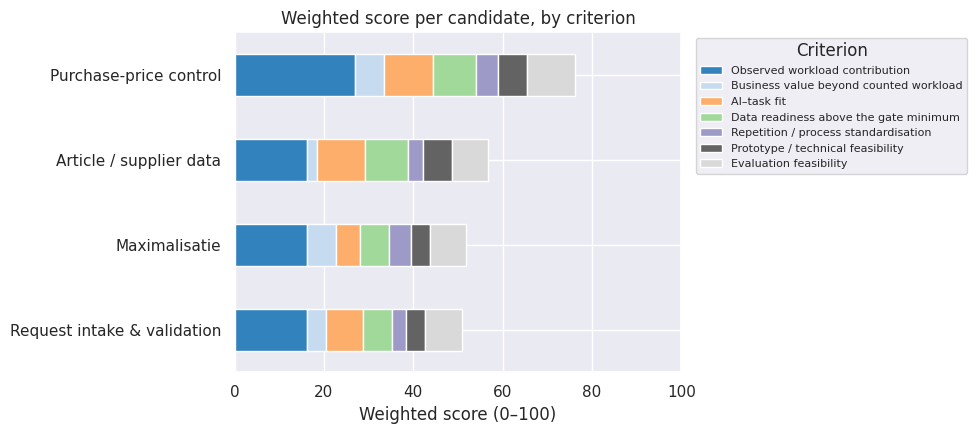

In [8]:
# Contribution of each criterion to each total
contributions = score_table.mul(weights["weight"], axis=1) / 5 * 100
contributions = contributions.loc[totals.index[::-1]]
contributions.columns = weights.loc[contributions.columns, "label"]

ax = contributions.plot(kind="barh", stacked=True, figsize=(10, 4.5), colormap="tab20c")
ax.set_xlabel("Weighted score (0–100)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Weighted score per candidate, by criterion")
ax.legend(title="Criterion", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
# The evidence behind each score
with pd.option_context("display.max_colwidth", 220, "display.max_rows", None):
    display(scored.sort_values(["candidate", "criterion"])[["candidate", "criterion", "score", "low", "high", "evidence"]])

,candidate,criterion,score,low,high,evidence
23,Article / supplier data,ai_fit,4,3,4,"Extracting item fields from supplier documents in different layouts is the core of the task; precedent Šimsa et al. (2023), a benchmark [AI table row 4]."
22,Article / supplier data,business_value,1,1,2,No effect named beyond buyer time.
24,Article / supplier data,data_readiness,3,2,4,"Article records exist; whether their source documents are linked is not yet known [checks AR1, AR2]."
27,Article / supplier data,evaluation,3,2,4,Existing article records can be the reference; few cases per week [check AR3].
26,Article / supplier data,prototype,3,2,4,"Can run on exported article records and supplier documents [checks G6, AR2]."
25,Article / supplier data,repetition,2,2,3,"Four of five days, 5 case-days; item data differ per article."
21,Article / supplier data,workload,3,3,3,"39 minutes (7.0%) on four days, 5 case-days; one case blocked for a day by missing data [notebook part 8]."
9,Maximalisatie,ai_fit,2,1,3,"The narrowed version is close to a rule (same supplier, open PO); AI only for matching demand descriptions [AI table row 8]."
8,Maximalisatie,business_value,3,2,3,"One effect named: each PO costs time and money (Dennis via Yijie, 2 October); example of 4 lines added to a 12-line PO (31 Aug OBS-15)."
10,Maximalisatie,data_readiness,2,1,3,Past advice and stock states are unlikely to be stored; open POs probably are [checks MX1–MX3].


**Reading.** Price control scores highest or joint highest on every criterion, so its lead does not depend on one weight. Its largest advantage is workload: the order checks take 17.5% of the recorded time, against 7–8% for the others in the form they are scored. It also leads on evaluation feasibility (4 against 3: an approved price per line is a clear reference answer for many cases, while the narrowed outputs of the others have a reference but few observed cases) and equals the best on AI–task fit, data readiness and prototype feasibility. Article data has a good AI fit but no business effect named. Maximalisatie's narrowed list is close to a rule. Request intake's narrowed retrieval is small and occurred on only three days.

## 4. Sensitivity check

The methodology asks whether the leading candidate stays ahead when the assumptions change. Checks 1–3 are the methodology's own; checks 4–7 add the price-only boundary and combinations of changes.

1. **Equal weights** instead of the swing weights.
2. **Each weight ±20%**, one at a time, with the weights rescaled to 100%.
3. **Each score ±1**, one at a time (kept between 1 and 5).
4. **Price-only boundary** for purchase-price control: 28 minutes (5.0%) instead of 98, which gives a workload score of 3.
5. **Combined changes**: the fewest one-point changes, within each score's low–high range, that put another candidate ahead.
6. **Stress test**: every score at its low value for the leader and at its high value for all others, at the same time.
7. **Random draws**: 10,000 draws, each score taken independently and uniformly from its low–high range. This is an illustration of the ranges, not a probability: the share depends on how the ranges were set and on the independent, uniform sampling.

In [10]:
# Low and high value of every score, and the leading candidate
low = scored.pivot(index="candidate", columns="criterion", values="low")[weights.index]
high = scored.pivot(index="candidate", columns="criterion", values="high")[weights.index]
leader = totals.index[0]
print("Leader:", leader)

Leader: Purchase-price control


In [11]:
# 1. Equal weights
equal = pd.Series(1 / len(weights), index=weights.index)
equal_totals = (score_table @ equal / 5 * 100).sort_values(ascending=False)
equal_totals.round(1)

candidate
Purchase-price control         71.4
Article / supplier data        54.3
Maximalisatie                  51.4
Request intake & validation    48.6
dtype: float64

In [12]:
# 2. Each weight 20% higher or lower, the others rescaled so the weights add up to 100%
rows = []
for criterion in weights.index:
    for change in [0.8, 1.2]:
        w = weights["weight"].copy()
        w[criterion] *= change
        w = w / w.sum()
        t = (score_table @ w / 5 * 100).sort_values(ascending=False)
        rows.append([criterion, f"{change - 1:+.0%}", t.index[0], t.iloc[0] - t.iloc[1]])
weight_checks = pd.DataFrame(rows, columns=["criterion", "weight_change", "leader", "lead_over_next"])
print("Leaders across the 14 weight changes:", weight_checks["leader"].value_counts().to_dict())
weight_checks.round(1)

Leaders across the 14 weight changes: {'Purchase-price control': 14}


,criterion,weight_change,leader,lead_over_next
0,workload,-20%,Purchase-price control,18.3
1,workload,+20%,Purchase-price control,20.5
2,business_value,-20%,Purchase-price control,19.0
3,business_value,+20%,Purchase-price control,19.9
4,ai_fit,-20%,Purchase-price control,20.0
5,ai_fit,+20%,Purchase-price control,18.9
6,data_readiness,-20%,Purchase-price control,20.1
7,data_readiness,+20%,Purchase-price control,18.8
8,repetition,-20%,Purchase-price control,19.5
9,repetition,+20%,Purchase-price control,19.5


In [13]:
# 3. Each score one point higher or lower, one at a time
rows = []
for candidate in score_table.index:
    for criterion in score_table.columns:
        for change in [-1, 1]:
            s = score_table.copy()
            s.loc[candidate, criterion] = min(5, max(1, s.loc[candidate, criterion] + change))
            t = (s @ weights["weight"] / 5 * 100).sort_values(ascending=False)
            rows.append([candidate, criterion, change, t.index[0], t.iloc[0] - t.iloc[1]])
score_checks = pd.DataFrame(rows, columns=["candidate", "criterion", "change", "leader", "lead_over_next"])
print("Leaders across the", len(score_checks), "score changes:", score_checks["leader"].value_counts().to_dict())
print("Smallest lead:", round(score_checks["lead_over_next"].min(), 1), "points")

Leaders across the 56 score changes: {'Purchase-price control': 56}
Smallest lead: 14.1 points


In [14]:
# 4. Price-only boundary for purchase-price control
price_only = score_table.copy()
price_only.loc["Purchase-price control", "workload"] = 3
price_only_totals = (price_only @ weights["weight"] / 5 * 100).sort_values(ascending=False)
price_only_totals.round(1)

candidate
Purchase-price control         65.4
Article / supplier data        56.8
Maximalisatie                  51.9
Request intake & validation    50.8
dtype: float64

In [15]:
# 5. Fewest one-point changes within the ranges that put another candidate ahead.
# Each change moves the gap by its weight x 20 points, so taking the largest changes first gives the fewest.
rows = []
for challenger in score_table.index.drop(leader):
    steps = []
    for c in score_table.columns:
        points = weights.loc[c, "weight"] * 20
        steps += [[f"{leader}: {c} -1", points]] * int(score_table.loc[leader, c] - low.loc[leader, c])
        steps += [[f"{challenger}: {c} +1", points]] * int(high.loc[challenger, c] - score_table.loc[challenger, c])
    steps = pd.DataFrame(steps, columns=["change", "points"]).sort_values("points", ascending=False, kind="stable")
    steps["gap_closed"] = steps["points"].cumsum()
    gap = totals.loc[leader, "total"] - totals.loc[challenger, "total"]
    if steps["gap_closed"].max() > gap:
        n = int((steps["gap_closed"] <= gap).sum()) + 1
        rows.append([challenger, gap, len(steps), n, "; ".join(steps["change"].head(n))])
    else:
        rows.append([challenger, gap, len(steps), np.nan, "not possible within the ranges"])
combined = pd.DataFrame(rows, columns=["challenger", "gap_points", "changes_available", "fewest_changes_needed", "those_changes"])
with pd.option_context("display.max_colwidth", 300):
    display(combined.round(1))

,challenger,gap_points,changes_available,fewest_changes_needed,those_changes
0,Article / supplier data,19.5,9,6.0,Purchase-price control: workload -1; Purchase-price control: data_readiness -1; Article / supplier data: data_readiness +1; Purchase-price control: ai_fit -1; Purchase-price control: evaluation -1; Article / supplier data: evaluation +1
1,Maximalisatie,24.3,7,NaN,not possible within the ranges
2,Request intake & validation,25.4,8,NaN,not possible within the ranges


In [16]:
# 6. Stress test: the leader at its low values, every other candidate at its high values
stress = high.copy()
stress.loc[leader] = low.loc[leader]
stress_totals = (stress @ weights["weight"] / 5 * 100).sort_values(ascending=False)
stress_totals.round(1)

candidate
Article / supplier data        68.6
Purchase-price control         62.2
Request intake & validation    61.1
Maximalisatie                  60.0
dtype: float64

In [17]:
# 7. Random draws: each score drawn independently and uniformly from its low-high range
rng = np.random.default_rng(20261007)
draws = 10000
wins = pd.Series(0, index=score_table.index)
tied_draws = 0
for _ in range(draws):
    s = pd.DataFrame(rng.integers(low.to_numpy(), high.to_numpy() + 1), index=low.index, columns=low.columns)
    # Integer swing-weight sums preserve the ranking without floating-point tie drift.
    draw_totals = s @ weights["swing"]
    leaders = draw_totals.index[draw_totals.eq(draw_totals.max())]
    if len(leaders) == 1:
        wins[leaders[0]] += 1
    else:
        tied_draws += 1

print("Strict wins by a candidate other than the main leader:", wins.sum() - wins[leader], "of", draws)
print("Draws tied for first place:", tied_draws, "of", draws)
pd.DataFrame({"strict_wins": wins, "share_of_all_draws_strictly_won_pct": wins / draws * 100}).sort_values("strict_wins", ascending=False).round(2)


Strict wins by a candidate other than the main leader: 8 of 10000
Draws tied for first place: 8 of 10000


,strict_wins,share_of_all_draws_strictly_won_pct
candidate,,
Purchase-price control,9984,99.84
Article / supplier data,8,0.08
Maximalisatie,0,0.00
Request intake & validation,0,0.00


In [18]:
# Summary of the checks
summary = pd.DataFrame([
    ["Swing weights (main result)", totals.index[0], totals["total"].iloc[0] - totals["total"].iloc[1]],
    ["1. Equal weights", equal_totals.index[0], equal_totals.iloc[0] - equal_totals.iloc[1]],
    ["2. Each weight ±20% (14 cases)", weight_checks["leader"].mode()[0] + f" in {(weight_checks['leader'] == leader).sum()} of 14", weight_checks["lead_over_next"].min()],
    ["3. Each score ±1 (" + str(len(score_checks)) + " cases)", score_checks["leader"].mode()[0] + f" in {(score_checks['leader'] == leader).sum()} of {len(score_checks)}", score_checks["lead_over_next"].min()],
    ["4. Price-only boundary", price_only_totals.index[0], price_only_totals.iloc[0] - price_only_totals.iloc[1]],
    ["5. Combined changes", leader + f" until {int(combined['fewest_changes_needed'].min())} one-point changes", np.nan],
    ["6. Stress test", stress_totals.index[0], stress_totals.iloc[0] - stress_totals.iloc[1]],
    ["7. Random draws (illustration)", wins.idxmax() + f": {wins.max()} strict wins; {tied_draws} draws tied for first", np.nan],
], columns=["check", "leader", "smallest_lead_points"])
summary.round(1)

,check,leader,smallest_lead_points
0,Swing weights (main result),Purchase-price control,19.5
1,1. Equal weights,Purchase-price control,17.1
2,2. Each weight ±20% (14 cases),Purchase-price control in 14 of 14,18.3
3,3. Each score ±1 (56 cases),Purchase-price control in 56 of 56,14.1
4,4. Price-only boundary,Purchase-price control,8.6
5,5. Combined changes,Purchase-price control until 6 one-point changes,NaN
6,6. Stress test,Article / supplier data,6.5
7,7. Random draws (illustration),Purchase-price control: 9984 strict wins; 8 dr...,NaN


**Reading.** Price control stays first in every single-change check: with equal weights (lead 17.1 points), with each weight ±20% (smallest lead 18.3), with each score ±1 (smallest lead 14.1) and with the price-only boundary, scored on the 28 minutes that name price (lead 8.6). By the methodology's own checks the ranking is therefore stable.

Combinations of plausible changes can reverse it. Six one-point changes within the recorded ranges put article data ahead: price control one point lower on workload, data readiness, AI–task fit and evaluation, and article data one point higher on data readiness and evaluation. Maximalisatie and request intake cannot overtake within their ranges. In the stress test, with every score at its worst for price control and its best for the others, article data leads (68.6 against 62.2). Among the 10,000 random draws, price control wins strictly in 9,984 and article data in 8; the two tie for first in another 8. Ties are reported separately rather than counted as wins or losses. These counts follow from the ranges and the independent, uniform sampling, so they illustrate the ranges rather than give a probability.

Four of the six reversing changes are price control's own data readiness, evaluation, workload and AI fit. The first two depend on the test account, so checks PC1–PC4 come first; if they fail, the question is no longer the score but gates 2 and 3.

## 5. The focal case

**Purchase-price control is the provisional focal case.**

**Task boundary** (brief, decision 5): checking supplier quotations before ordering and order confirmations after ordering against the PO and supplier information, with price as the main reported problem. Recorded workload: 98 of 560 minutes (17.5%) on all five days, of which 28 minutes are in records that name price explicitly.

**Proposed support, to be designed in Improve:** read the price, quantity and delivery date per line from the quotation or confirmation (scan, PDF, email or website), match the lines to the PO, and flag differences for the buyer. Within the standard / review / manual frame, lines without a difference follow the standard route and flagged lines go to the buyer for review. Nothing changes in Exact without the buyer, which stays within the buyers' concern of 1 October about autonomous order preparation.

**Conditions before Improve.** One condition of the provisional selection is met: Johan's permission covers the test-account data and processing its documents with an external AI service (checks G1–G2, confirmed by Yijie on 7 October), so gate 1 passes and the prototype may use an external AI service. Four remain:

1. The test account holds POs with their confirmations or quotations, and the approved price per line can be traced (checks PC1–PC4). If not, gates 2 and 3 reopen for price control: an alternative source, such as recent confirmations from the buyers' mailbox with the price recorded in Exact after the buyer's check as the reference, needs Johan's permission and must be shown to be representative and to give correct answers before Stage A is reassessed and scoring continues. A lower data-readiness score does not settle this, and test workloads built from past orders set the size of a test, not its correct answers.
2. Arno accepts that price and date differences are flagged for his review (session guide, part D, rows 5–6).
3. Zhongxin agrees with the gates, the scores and the focal case after setting her own weights without seeing Yijie's scores; her weights are added to the sensitivity check.
4. Johan confirms the business value of the proposed focal case. Permission to process test-account documents does not itself establish that business value.

The targeted classification review in the analysis notebook checks the workload evidence used here; any consequential correction must be carried into this comparison. Use the Stage A worksheet for the checks needed to settle the chosen case and any fallback. Completing every worksheet row or another general observation round is not a separate condition for proceeding.

**The other candidates:**

- **Article / supplier data** is the runner-up (56.8) and the first fallback if price control fails its gates; its own gates 2–3 depend on checks AR1–AR2.
- **Maximalisatie** and **request intake & validation** stay as further opportunities in their narrowed form.
- **PO supplier communication** becomes a quick-win recommendation with ordinary automation, outside the AI artifact.
- **Standard / review / manual** is the design frame of the focal case.

**Limitations.** One assessor so far; Zhongxin's review follows. The evidence comes from five partial sessions of one buyer, and the decision-relevant and ambiguous kinds-of-work assignments across competing candidates still await the targeted human review. Overall inter-coder reliability is not established. The optional 45-record sample is not a mandatory closeout task, and an observed case without a recorded problem is not proof of a routine or automatable case. The workload figures were known before the weights were set; the weights were recorded before any scoring. The verdicts and scores were drafted from the evidence matrix with AI assistance and reviewed by Yijie.